In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]

import numpy as np
import torch
import arviz as az
import matplotlib.pyplot as plt
import xarray
from ICIW_Plots import figure, make_rect_ax, make_square_ax, cm2inch
from scipy.stats.qmc import LatinHypercube, scale

plt.style.use("ICIWstyle")

In [2]:
from HSA_Cam_B_028_pyro import (  # heteroscedastic
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    kl_divergence_between_models,
)
from HSA_Mo_B_011_pyro import kinetics_model  # heteroscedastic

In [3]:
params = {
    "T": (450.0, 600.0),
    "p": (3.0, 9.0),
    "c2h": (0.2, 4.0),
    "c2m": (0.5, 1000.0),
    "c2w": (0.5, 1000.0),
    "c2i": (0.05, 1.0),
}

# Generate the space filling design points

In [4]:
num_samples = 1000
LHsampler = LatinHypercube(d=len(params))
samples = LHsampler.random(n=num_samples)
samples = scale(
    samples, [v[0] for v in params.values()], [v[1] for v in params.values()]
)

samples = xarray.DataArray(
    data=samples,
    dims=["sample", "parameter"],
    coords={"parameter": list(params.keys())},
)
display(samples)

<xarray.DataArray (sample: 1000, parameter: 6)> Size: 48kB
array([[4.57508759e+02, 7.68241042e+00, 2.90686196e+00, 9.82319106e+02,
        6.69945129e+02, 6.31152961e-01],
       [4.94834881e+02, 4.07660903e+00, 1.32067171e+00, 8.92250189e+00,
        3.20555571e+02, 1.22639996e-01],
       [5.31133011e+02, 5.37133738e+00, 2.88316287e+00, 6.45152659e+02,
        1.87913851e+02, 9.73576463e-01],
       ...,
       [5.56498730e+02, 4.77950988e+00, 8.05132922e-01, 5.39624091e+01,
        2.23381378e+02, 2.99003085e-01],
       [5.75372301e+02, 7.75713119e+00, 2.00613004e+00, 4.09396428e+02,
        7.84260930e+02, 5.85406387e-01],
       [4.92595449e+02, 4.10890554e+00, 3.39494812e+00, 1.12297984e+02,
        8.52320442e+02, 1.87613546e-01]], shape=(1000, 6))
Coordinates:
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
Dimensions without coordinates: sample

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\stats\density_utils.py:250: RuntimeWarning: divide by zero encountered in scalar power
  out = t - (2 * N * np.pi**0.5 * f) ** (-0.4)


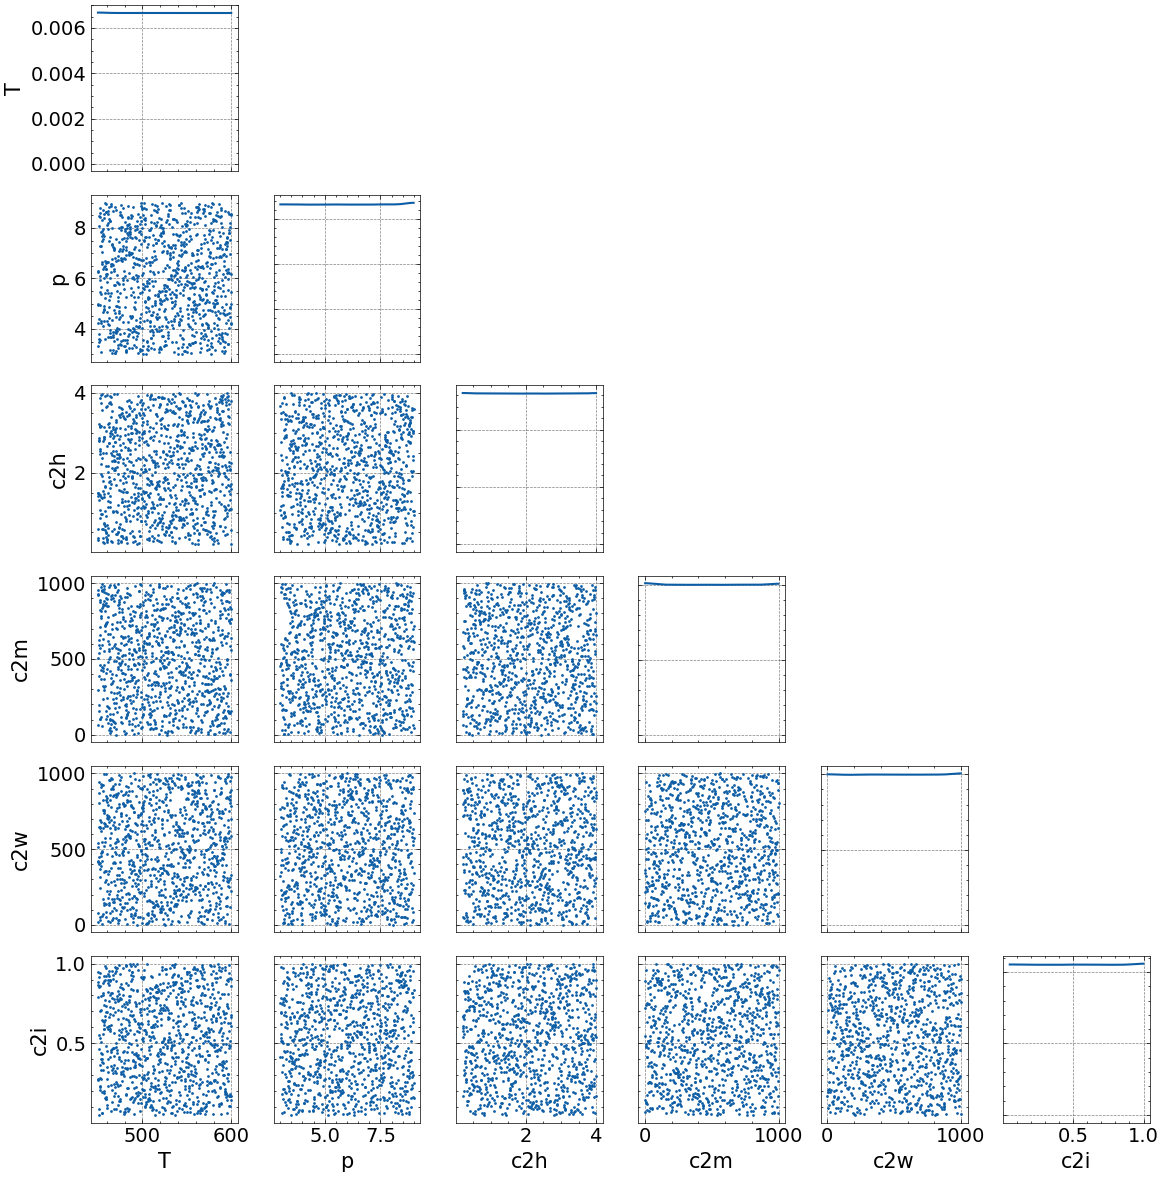

In [5]:
# Convert samples to a format suitable for arviz pair plot
sample_dict = {param: samples.sel(parameter=param).values for param in params.keys()}

az.plot_pair(sample_dict, kind="scatter", marginals=True, figsize=(12, 12))
plt.tight_layout()
plt.show()

Pretty space filling!

## Generate the GT model predictions at these positions

In [6]:
T, p, lat_r = generate_synthetic_data(
    torch.tensor(samples.sel(parameter="T").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="p").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2h").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2m").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2w").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2i").values).reshape(-1, 1),
    rel_noise_std=0.0,
)
T, p, obs_r = generate_synthetic_data(
    torch.tensor(samples.sel(parameter="T").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="p").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2h").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2m").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2w").values).reshape(-1, 1),
    torch.tensor(samples.sel(parameter="c2i").values).reshape(-1, 1),
    rel_noise_std=0.1,
)

array([[<Axes: title={'center': 'lat_r'}>,
        <Axes: title={'center': 'obs_r'}>]], dtype=object)

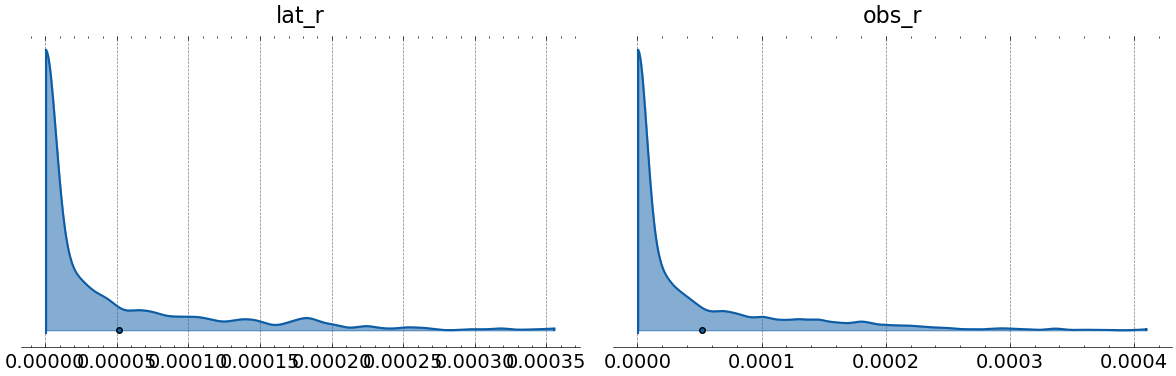

In [7]:
az.plot_density(
    {
        "lat_r": lat_r.numpy().flatten(),
        "obs_r": obs_r.numpy().flatten(),
    },
    figsize=(12, 4),
    hdi_prob=0.999,
    shade=0.5,
)
# ax = plt.gca()
# ax.set_xscale("log")

array([[<Axes: title={'center': 'lat_r'}>]], dtype=object)

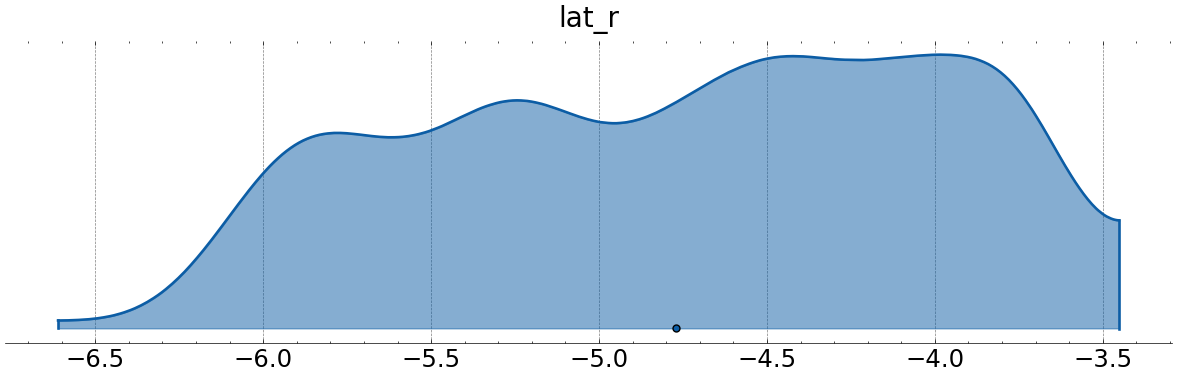

In [8]:
az.plot_density(
    {
        "lat_r": np.log10(lat_r.numpy().flatten()),
    },
    figsize=(12, 4),
    hdi_prob=0.999,
    shade=0.5,
)

In [9]:
data = xarray.Dataset(
    {
        "samples": samples,
        "T": (("sample"), T.numpy().flatten()),
        "p": (("sample", "species"), p.numpy()),
        "latent_r": (("sample"), lat_r.numpy().flatten()),
        "obs_r": (("sample"), obs_r.numpy().flatten()),
    },
    coords={
        "sample": np.arange(num_samples),
        "species": ["CO2", "H2", "H2O", "CH4", "I"],
    },
)
data.attrs["noise"] = "heteroscedastic"
data.attrs["sigma"] = 0.1
display(data)

data.to_netcdf(Path("data/test_HSA_Da_B_003.nc"))

<xarray.Dataset> Size: 120kB
Dimensions:    (parameter: 6, sample: 1000, species: 5)
Coordinates:
  * parameter  (parameter) <U3 72B 'T' 'p' 'c2h' 'c2m' 'c2w' 'c2i'
  * sample     (sample) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
  * species    (species) <U3 60B 'CO2' 'H2' 'H2O' 'CH4' 'I'
Data variables:
    samples    (sample, parameter) float64 48kB 457.5 7.682 ... 852.3 0.1876
    T          (sample) float64 8kB 457.5 494.8 531.1 ... 556.5 575.4 492.6
    p          (sample, species) float64 40kB 2.621 0.9017 ... 0.005515 3.301
    latent_r   (sample) float64 8kB 1.018e-06 3.899e-06 ... 0.0001437 3.04e-06
    obs_r      (sample) float64 8kB 9.717e-07 3.184e-06 ... 0.0001395 3.11e-06
Attributes:
    noise:    heteroscedastic
    sigma:    0.1